In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import cv2
from functions import *


 

### Read Orginal RGB Image from Current path

In [4]:

# path = cv2.imread("C:\programming\pythonML\computerVision\BCancer.jpeg")

# Load the image (auto-detect mode)
image = cv2.imread("C:/programming/pythonML/computerVision/Breast_cancer/datasets/20588190 (2).png", cv2.IMREAD_UNCHANGED)

# Check if it's already grayscale
if len(image.shape) == 2 or image.shape[2] == 1:
    gray_image = image  # Already grayscale
    print("Image is already grayscale.")
else:
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    print("Converted BGR to grayscale.")
    # Resize image (example: 512x512)
gray_image = cv2.resize(gray_image, (150, 200), interpolation=cv2.INTER_AREA)

# Show and save
cv2.imshow("Grayscale", gray_image)
cv2.imwrite("gray_image.jpg", gray_image)



Converted BGR to grayscale.


True

In [5]:
image = gray_image
# Create a mask by thresholding (background is dark)
_, mask = cv2.threshold(image, 30, 255, cv2.THRESH_BINARY)

# Clean up mask with morphology
kernel = np.ones((3,3), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=2)
mask = cv2.morphologyEx(mask, cv2.MORPH_DILATE, kernel, iterations=1)

# Apply mask to keep only foreground
bg_removed = cv2.bitwise_and(image, image, mask=mask)



(np.float64(-0.5), np.float64(149.5), np.float64(199.5), np.float64(-0.5))

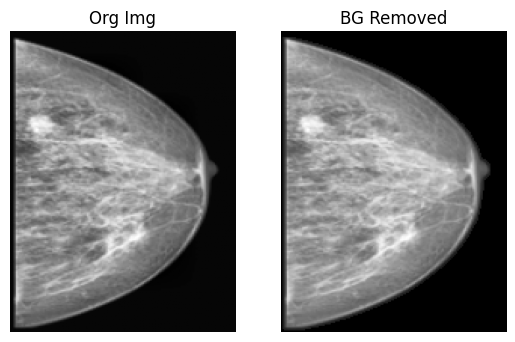

In [6]:
plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray') 
plt.title('Org Img')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(bg_removed, cmap='gray'), plt.title('BG Removed')
plt.axis('off')


### Feature extraction filter hexgonal version

In [7]:
print("size=",bg_removed.size, cv2.cvtColor(bg_removed, cv2.COLOR_BGR2RGB).shape)

size= 30000 (200, 150, 3)


In [8]:
# kernel = np.array([[0, -1, 0],
#                    [-1, 5, -1],
#                    [0, -1, 0]])
# #Enhancement Filter using VHT
# e = cff_enhance = 14
# vht_enhance = np.array([[1/e, 0, 1/e],
#                         [2/e, 6/e, 2/e],
#                         [1/e, 0/e, 1/e]])

# img = cv2.filter2D( -1, vht_enhance)

#Feature Extraction Filter using VHT both "X" and "Y" Direction
###############  Along X-axis  #############
f = cff_feature_x = 2
vht_feature_x = np.array([[-1/f, 0, 1/f],
                        [-2/f, 2, 2/f],
                        [-1/f, 0, 1/f]])

img_x = cv2.filter2D(bg_removed, -1, vht_feature_x)
###############  Along Y-axis  #############
f = cff_feature_y = 2
vht_feature_y = np.array([[-1/f, -2/f, -1/f],
                          [ 0,     2,    0],
                          [1/f,    2/f,  1/f]])

img_y = cv2.filter2D(bg_removed, -1, vht_feature_y)

###############  Along DX-axis  #############
f = cff_feature_dx = 2
vht_feature_dx = np.array([[0,   -1/f,   -2/f],  
                           [1/f,   3/f,    -1/f],
                           [2/f,   1/f,    0]])

img_dx = cv2.filter2D(bg_removed, -1, vht_feature_dx)

###############  Along DY-axis  #############
f = cff_feature_dy = 2
vht_feature_dy = np.array([[-2/f,   -1/f,    0],
                          [ -1/f,    3/f,    1/f],
                          [  0,      1/f,    2/f]])

img_dy = cv2.filter2D(bg_removed, -1, vht_feature_dy)

### Edge Detection Filters Hex-version

In [9]:
edge_filter_45 = np.array([[ 2, 2, 0],
                            [-2, 0, 2],
                            [0, -2, -2]])
edge_filter_y = np.array([[2,  0,  -2],
                          [2,  0,  -2],
                          [2,  0,  -2]])
edge_filter_135 = np.array([[ 0, 2, 2],
                            [-2, 0, 2],
                            [-2, -2, 0]])
edge_filter_x = np.array([[ 2,  2,  2],
                          [ 0,  0,  0],
                          [-2, -2, -2]])

In [10]:
## Effect of edge filter wiht gray scale image
Edge_result_45 = cv2.bitwise_not(cv2.filter2D(bg_removed, -1, edge_filter_45))

Edge_result_y = cv2.bitwise_not(cv2.filter2D(bg_removed, -1, edge_filter_y))
Edge_result_135 = cv2.bitwise_not(cv2.filter2D(bg_removed, -1, edge_filter_135))
Edge_result_x = cv2.bitwise_not(cv2.filter2D(bg_removed, -1, edge_filter_x))

edge_x_y_combined = cv2.bitwise_not(np.maximum(Edge_result_x, Edge_result_y))
edge_45_135_combined = cv2.bitwise_not(np.maximum(Edge_result_45, Edge_result_135))





In [ ]:
print("size of filter = ", edge_filter_x.size, "and shape = ", edge_filter_x.shape)
print("size of image = ", Edge_result_x.size, "and shape = ", Edge_result_x.shape)

size of filter =  9 and shape =  (3, 3)
size of image =  30000 and shape =  (200, 150)


In [11]:
def fuse_four_images(img1, img2, img3, img4):
    # Resize all images to the same shape (based on first image)
    h, w = img1.shape[:2]
    img2 = cv2.resize(img2, (w, h))
    img3 = cv2.resize(img3, (w, h))
    img4 = cv2.resize(img4, (w, h))

    # Convert all to float for accurate averaging
    fused = (img1.astype(np.float32) +
             img2.astype(np.float32) +
             img3.astype(np.float32) +
             img4.astype(np.float32)) / 4.0

    # Convert back to uint8
    fused = np.clip(fused, 0, 255).astype(np.uint8)
    return fused
result = fuse_four_images(Edge_result_x, Edge_result_y, Edge_result_45, Edge_result_135)

vht_x = cv2.filter2D(gray_image, -1, edge_filter_x)
vht_y = cv2.filter2D(gray_image, -1, edge_filter_y)
vht_45 =cv2.filter2D(gray_image, -1, edge_filter_45)
vht_135 =cv2.filter2D(gray_image, -1, edge_filter_135)

result_dark = fuse_four_images(vht_x, vht_y, vht_45, vht_135)

ValueError: Unrecognized string '' to axis; try 'on' or 'off'

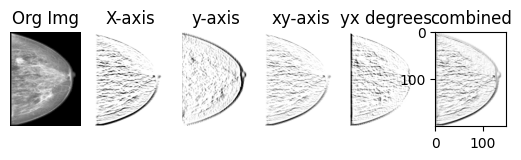

In [ ]:

plt.subplot(1, 6, 1)
plt.imshow(bg_removed, cmap='gray'), plt.title('Org Img')
plt.axis('')
plt.subplot(1, 6, 2)
plt.imshow(Edge_result_x, cmap='gray'), plt.title('X-axis')
plt.axis('')
plt.subplot(1, 6, 3)
plt.imshow(Edge_result_y, cmap='gray'), plt.title('y-axis')
plt.axis('')
plt.subplot(1, 6, 4)
plt.imshow(Edge_result_45, cmap='gray'), plt.title('xy-axis')
plt.axis('')
plt.subplot(1, 6, 5)
plt.imshow(Edge_result_135, cmap='gray'), plt.title('yx degrees')
plt.axis('')
plt.subplot(1, 6, 6)
plt.imshow(result, cmap='gray')
plt.title('combined')
plt.axis('')
plt.tight_layout()
plt.show()

cv2.imwrite("combined.jpg", result)
# write = cv2.imwrite("C:\programming\pythonML\computerVision\BCancer_edge.png", edge_filter_y)



Saved: connected_edges_colored.png


(np.float64(-0.5), np.float64(149.5), np.float64(199.5), np.float64(-0.5))

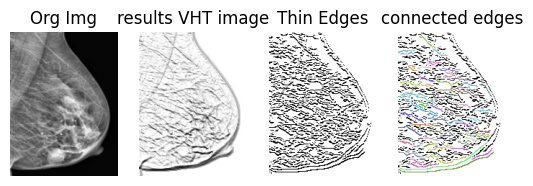

In [ ]:
import cv2
import numpy as np
from skimage.morphology import skeletonize
from skimage import img_as_ubyte

# Read image
image = cv2.bitwise_not(cv2.imread("combined.jpg", cv2.IMREAD_GRAYSCALE))

# Step 1: Edge detection (Canny for continuous edges)
edges = cv2.Canny(image, 80, 200)

# Step 2: Convert to binary (0 and 1) for skeletonization
binary = edges > 0

# Step 3: Apply skeletonization (thinning)
skeleton = skeletonize(binary)

# Step 4: Convert skeleton back to uint8
thin_edges = img_as_ubyte(skeleton)

thin_edges = cv2.bitwise_not(cv2.filter2D(thin_edges, -1, edge_filter_x))

##### Check if the edges are connectd, if connected show in color
min_area = 30               # pixels: components smaller than this will be black

# --- Load image ---
img = thin_edges

# --- Threshold and invert ---
# Inversion so that edges become white (foreground)
_, binary_inv = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY_INV)

# --- Connected components ---
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary_inv, connectivity=8)

# --- Prepare output: original grayscale background ---
output = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

# --- Color components ---
np.random.seed(1)  # for reproducible colors
for label in range(1, num_labels):  # skip label 0 (background)
    area = stats[label, cv2.CC_STAT_AREA]
    mask = labels == label
    if area >= min_area:
        color = tuple(np.random.randint(50, 230, 3).tolist())  # bright colors
        output[mask] = color
    else:
        output[mask] = (0, 0, 0)  # small/non-connected -> black

# --- Save result ---
out_path = 'connected_edges_colored.png'
cv2.imwrite(out_path, output)
print(f"Saved: {out_path}")

##### 

plt.subplot(1, 4, 1)
plt.imshow(gray_image, cmap='gray'), plt.title('Org Img')
plt.axis('off')
plt.subplot(1, 4, 2)
plt.imshow(cv2.bitwise_not(image), cmap='gray'), plt.title('results VHT image')
plt.axis('off')
plt.subplot(1, 4, 3)
plt.imshow(thin_edges, cmap='gray'), plt.title('Thin Edges')
plt.axis('off')
plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB)), plt.title('connected edges')
plt.axis('off')




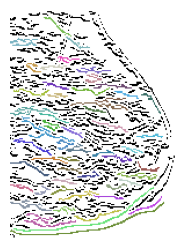

In [ ]:
# --- Show result ---
plt.figure(figsize=(3, 3))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.axis('off')
# plt.title(f'Connected components colored (min_area={min_area})')
plt.show()


(200, 150)


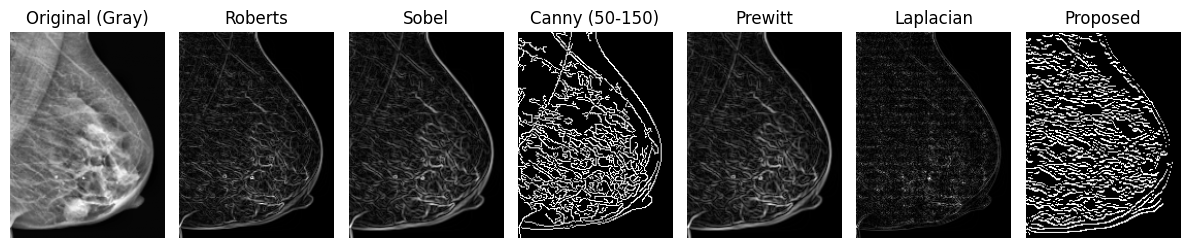

In [ ]:

from skimage import filters, io, color

image_gray = gray_image

# Roberts
roberts_edges = filters.roberts(image_gray)

# Sobel
sobel_edges = filters.sobel(image_gray)

# Canny
canny_edges = cv2.Canny(image_gray, 50, 150)
# canny_edges_100_200 = cv2.Canny(image_gray, 100, 200)

# Laplacian for comparison
laplacian_edges = cv2.Laplacian(image_gray, cv2.CV_64F)
laplacian_edges = np.uint8(np.absolute(laplacian_edges))

# Prewitt (optional)
prewitt_edges = filters.prewitt(image_gray)
print(prewitt_edges.shape)

# Plot results in 2×4 grid
fig, ax = plt.subplots(1, 7, figsize=(12, 6))

ax[0].imshow(image_gray, cmap='gray')
ax[0].set_title("Original (Gray)")

ax[1].imshow(roberts_edges, cmap='gray')
ax[1].set_title("Roberts")

ax[2].imshow(sobel_edges, cmap='gray')
ax[2].set_title("Sobel")

ax[3].imshow(canny_edges, cmap='gray')
ax[3].set_title("Canny (50-150)")

ax[4].imshow(prewitt_edges, cmap='gray')
ax[4].set_title("Prewitt")

ax[5].imshow(laplacian_edges, cmap='gray')
ax[5].set_title("Laplacian")

# result_dark = cv2.resize(result_dark, (150, 170), interpolation=cv2.INTER_AREA)  # Resize to match other images

ax[6].imshow(cv2.bitwise_not(thin_edges), cmap='gray')
ax[6].set_title("Proposed")

for a in ax.ravel():
    a.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
#################       edge thinning another method may be can used any other time
# # Assuming edge_filter_x and edge_filter_y are float arrays
# image = gray_image

# # Step 0: Prepare for Canny
# image_abs = np.abs(image)  # Remove negative values
# image_norm = cv2.normalize(image_abs, None, 0, 255, cv2.NORM_MINMAX)  # Scale to 0-255
# image_uint8 = image_norm.astype(np.uint8)  # Convert to 8-bit

# # Step 1: Edge detection
# edges = cv2.Canny(image_uint8, 100, 200)


# # Step 2: Thinning (opencv-contrib-python required)
# thinned_edges = cv2.ximgproc.thinning(edges, thinningType=cv2.ximgproc.THINNING_ZHANGSUEN)

# # Step 3: Blend with thinning factor
# thinning_factor = 2
# blended_edges = cv2.addWeighted(edges, 1 - thinning_factor, thinned_edges, thinning_factor, 0)

# edges_vis = cv2.dilate(edges, np.ones((2,2), np.uint8))
# thinned_vis = cv2.dilate(thinned_edges, np.ones((2,2), np.uint8))
# blended_vis = cv2.dilate(blended_edges, np.ones((2,2), np.uint8))


# plt.figure(figsize=(12, 4))

# plt.subplot(1, 3, 1)
# plt.imshow(edges_vis, cmap='gray')
# plt.title('Original Edges (Canny)')
# plt.axis('off')

# plt.subplot(1, 3, 2)
# plt.imshow(thinned_vis, cmap='gray')
# plt.title('Thinned Edges')
# plt.axis('off')

# plt.subplot(1, 3, 3)
# plt.imshow(blended_vis, cmap='gray')
# plt.title(f'Blended (factor={thinning_factor})')
# plt.axis('off')

# plt.tight_layout()
# plt.show()


In [ ]:
print("size of image = ", (Edge_result_x.size)/1024,"KB", "and shape = ", Edge_result_x.shape, "type is =", Edge_result_x.dtype)

size of image =  29.296875 KB and shape =  (200, 150) type is = uint8


In [ ]:
# count number of edge in the iamge

edges_NIVHT_combined = np.sum(Edge_result_x +Edge_result_y+Edge_result_45+Edge_result_135 > 0)
print(f"Number of NIVHT edges: {edges_NIVHT_combined}")

edges_NIVHT_robert = np.sum(roberts_edges > 0)
print(f"Number of roberts edges : {edges_NIVHT_robert}")

edges_NIVHT_sobel = np.sum(sobel_edges > 0)
print(f"Number of sobel edges : {edges_NIVHT_sobel}")

edges_NIVHT_canny = np.sum(canny_edges > 0)
print(f"Number of canny edges : {edges_NIVHT_canny}")

edges_NIVHT_prewite = np.sum(prewitt_edges > 0)
print(f"Number of prewitt_edges: {edges_NIVHT_prewite}")

edges_NIVHT_laplacian = np.sum(laplacian_edges > 0)
print(f"Number of laplacian edges : {edges_NIVHT_laplacian}")

#------------ EPI calculation ----------------
## NIVHT EPI calculation
epi_NIVHT_x = calculate_epi(image, Edge_result_x)
print("EPI value DG-x = ", epi_NIVHT_x)
epi_NIVHT_y = calculate_epi(image, Edge_result_y)
print("EPI value DG-y= ", epi_NIVHT_y)

epi_NIVHT_45 = calculate_epi(image, Edge_result_45)
print("EPI value DG-xy = ", epi_NIVHT_45)
epi_NIVHT_135 = calculate_epi(image, Edge_result_135)
print("EPI value DG-xy= ", epi_NIVHT_135)

epi_NIVHT_Combined = calculate_epi(image, result)
print("EPI value DG-combined= ", epi_NIVHT_Combined)

## EPI Other Classical Filter for Edge detection
epi_robert = calculate_epi(image, roberts_edges)
print("EPI value Robert= ", epi_robert)

epi_sobel = calculate_epi(image, sobel_edges)
print("EPI value Sobel= ", epi_sobel)

epi_canny= calculate_epi(image, canny_edges)
print("EPI value Canny= ", epi_canny)

epi_prewite = calculate_epi(image, prewitt_edges)
print("EPI value Prewite= ", epi_prewite)

epi_laplacian = calculate_epi(image, laplacian_edges)
print("EPI value Laplacian= ", epi_laplacian)



Number of NIVHT edges: 29944
Number of roberts edges : 23053
Number of sobel edges : 29975
Number of canny edges : 5363
Number of prewitt_edges: 29919
Number of laplacian edges : 23156
EPI value DG-x =  0.93908453
EPI value DG-y=  0.3315998
EPI value DG-xy =  0.9387181
EPI value DG-xy=  0.80552024
EPI value DG-combined=  0.99951434
EPI value Robert=  0.4368835
EPI value Sobel=  0.56861424
EPI value Canny=  0.4107421
EPI value Prewite=  0.57330287
EPI value Laplacian=  0.4685856


In [ ]:
def count_connected_edges(edge_image):
    # Ensure binary image is 0 and 255
    binary = (edge_image > 0).astype(np.uint8)

    # Find connected components
    num_labels, labels = cv2.connectedComponents(binary)

    # Subtract 1 to ignore background
    return num_labels - 1, labels

connected_edge_NIVHT, labels = count_connected_edges(edge_x_y_combined+edge_45_135_combined)
print("NIVHT-X Connected edges= ", connected_edge_NIVHT)

connected_edge_robert, labels = count_connected_edges(roberts_edges)
print("Robert Connected edges= ", connected_edge_robert)
connected_edge_sobel, labels = count_connected_edges(sobel_edges)
print("Sobel Connected edges= ", connected_edge_sobel)
connected_edge_canny, labels = count_connected_edges(canny_edges)
print("Canny Connected edges= ", connected_edge_canny)
connected_edge_prewit, labels = count_connected_edges(prewitt_edges)
print("Prewite Connected edges= ", connected_edge_prewit)
connected_edge_laplacian, labels = count_connected_edges(laplacian_edges)
print("Laplacian Connected edges= ", connected_edge_laplacian)
     

NIVHT-X Connected edges=  63
Robert Connected edges=  1
Sobel Connected edges=  1
Canny Connected edges=  55
Prewite Connected edges=  1
Laplacian Connected edges=  1


In [ ]:
from skimage.measure import shannon_entropy
# Functions here
def image_entropy(image):
    """
    Calculate the Shannon entropy of an image.
    Works for grayscale or color images.
    """
    # Convert to grayscale if color
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return shannon_entropy(image)


##### Other Qalitfing factors

entropy_NIVHT_X =  round(image_entropy(Edge_result_x), 2)
print("Entropy value NIVHT-x= ", entropy_NIVHT_X)
entropy_NIVHT_Y = round(image_entropy(Edge_result_y), 2)
print("Entropy value NIVHT-y= ", entropy_NIVHT_Y)
entropy_NIVHT_45 = round(image_entropy(Edge_result_45), 2)
print("Entropy value NIVHT-xy= ", entropy_NIVHT_45)
entropy_NIVHT_135 = round(image_entropy(Edge_result_135), 2)
print("Entropy value NIVHT-yx= ", entropy_NIVHT_135)
entropy_NIVHT_Combined = round(image_entropy(Edge_result_x+Edge_result_y+Edge_result_45+Edge_result_135), 2)
print("Entropy value NIVHT-combined= ", entropy_NIVHT_Combined)
### Classical edge detection ssim
entropy_robert = round(image_entropy(roberts_edges), 2)
print("Entropy value Robert= ", entropy_robert)
entropy_sobel = round(image_entropy(sobel_edges), 2)
print("Entropy value Sobel= ", entropy_sobel)
entropy_canny = round(image_entropy(canny_edges), 2)
print("Entropy value Canny= ", entropy_canny)
entropy_prewite = round(image_entropy(prewitt_edges), 2)
print("Entropy value Prewite= ", entropy_prewite)
entropy_laplacian = round(image_entropy(laplacian_edges), 2)
print("Entropy value Laplacian= ", entropy_laplacian)

Entropy value NIVHT-x=  3.41
Entropy value NIVHT-y=  3.46
Entropy value NIVHT-xy=  3.3
Entropy value NIVHT-yx=  3.29
Entropy value NIVHT-combined=  5.56
Entropy value Robert=  8.4
Entropy value Sobel=  11.4
Entropy value Canny=  0.68
Entropy value Prewite=  11.38
Entropy value Laplacian=  4.74


In [ ]:
# Create DataFrame
data = {
    "Method": ["Robert", "Sobel", "Canny", "Prewitt", "Laplacian", "NIVHT"],
    "Number_of_edges": [
        roberts_edges, sobel_edges, canny_edges, prewitt_edges, laplacian_edges, edges_NIVHT_combined
    ],
    "EPI": [
        epi_robert, epi_sobel, epi_canny, epi_prewite, epi_laplacian, epi_NIVHT_Combined
    ],
    "Connected_edges": [
        connected_edge_robert, connected_edge_sobel, connected_edge_canny, connected_edge_prewit, connected_edge_laplacian, connected_edge_NIVHT
    ],
    "MSE": [
        entropy_robert, entropy_sobel, entropy_canny, entropy_prewite, entropy_laplacian, entropy_NIVHT_Combined
    ],
    "Entropy": [
        entropy_robert, entropy_sobel, entropy_canny, entropy_prewite, entropy_laplacian, entropy_NIVHT_Combined
    ]
}

df = pd.DataFrame(data)

# Restrict to 2 decimal places
df = df.round(2)

# Export to Excel
df.to_excel("edge_detection_results.xlsx", index=False)

print("Table exported to edge_detection_results.xlsx")

Table exported to edge_detection_results.xlsx


In [35]:
import cv2
import numpy as np
import time
import pandas as pd
from skimage import filters
from skimage import io, img_as_float

# -----------------------
# Your proposed NIVHT function (placeholder)
# -----------------------
def nivht_operator(image):
    # Replace Edge_result_x and Edge_result_y with actual processing logic
    # Example placeholders:
    Edge_result_x = cv2.Sobel((image*255).astype(np.uint8), cv2.CV_64F, 1, 0, ksize=3)
    Edge_result_y = cv2.Sobel((image*255).astype(np.uint8), cv2.CV_64F, 0, 1, ksize=3)
    edge_x_y_combined = cv2.bitwise_not(np.maximum(Edge_result_x, Edge_result_y).astype(np.uint8))
    return edge_x_y_combined

# -----------------------
# Operators dictionary
# -----------------------
methods = {
    "Roberts": lambda img: filters.roberts(img),
    "Sobel": lambda img: filters.sobel(img),
    "Canny": lambda img: cv2.Canny((img*255).astype(np.uint8), 100, 200),
    "Prewitt": lambda img: filters.prewitt(img),
    "Laplacian": lambda img: cv2.Laplacian((img*255).astype(np.uint8), cv2.CV_64F),
    "NIVHT": lambda img: nivht_operator(img)
}

# -----------------------
# Measure computation times (in milliseconds)
# -----------------------
times = {}
outputs = {}
for name, func in methods.items():
    start_time = time.time()
    result = func(image)
    end_time = time.time()
    
    elapsed_ms = (end_time - start_time) * 1000  # convert to milliseconds
    times[name] = elapsed_ms
    outputs[name] = result

# -----------------------
# Compare with NIVHT
# -----------------------
nivht_time = times["NIVHT"]
time_diffs = {name: times[name] - nivht_time for name in times}

# -----------------------
# Create results table
# -----------------------
df = pd.DataFrame({
    "Method": list(times.keys()),
    "Time (ms)": [round(times[m], 3) for m in times],
    "Difference from NIVHT (ms)": [round(time_diffs[m], 3) for m in time_diffs]
})

# Save to Excel
df.to_excel("edge_detection_time_comparison_ms.xlsx", index=False)

print(df)


      Method  Time (ms)  Difference from NIVHT (ms)
0    Roberts      0.997                      -0.004
1      Sobel      1.004                       0.003
2      Canny      0.509                      -0.492
3    Prewitt      1.012                       0.011
4  Laplacian      0.000                      -1.001
5      NIVHT      1.001                       0.000


original shape: (200, 150) dtype: uint8
processed gray shape: (200, 150) dtype: uint8


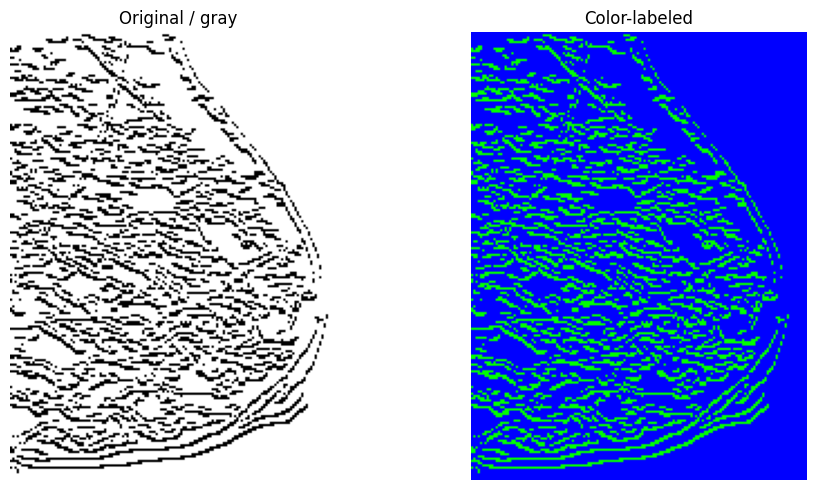

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---- input image variable ----
gray = thin_edges  # whatever you already have

# ---- Ensure grayscale is 2D ----
print("original shape:", getattr(gray, "shape", None), "dtype:", getattr(gray, "dtype", None))

if len(gray.shape) == 3:
    # handle common channel counts
    if gray.shape[2] == 3:
        gray2 = cv2.cvtColor(gray, cv2.COLOR_BGR2GRAY)
    elif gray.shape[2] == 4:
        # try BGRA -> GRAY; if that fails try RGBA
        try:
            gray2 = cv2.cvtColor(gray, cv2.COLOR_BGRA2GRAY)
        except Exception:
            gray2 = cv2.cvtColor(gray, cv2.COLOR_RGBA2GRAY)
    else:
        # fallback: collapse channels by averaging
        gray2 = np.mean(gray, axis=2)
else:
    gray2 = gray.copy()

# Normalize & force uint8
gray2 = cv2.normalize(gray2, None, 0, 255, cv2.NORM_MINMAX)
gray2 = gray2.astype(np.uint8)
print("processed gray shape:", gray2.shape, "dtype:", gray2.dtype)

# ---- Color mapping ----
h, w = gray2.shape
color_image = np.zeros((h, w, 3), dtype=np.uint8)

low_thresh = 85
high_thresh = 170

mask_low  = gray2 <= low_thresh
mask_mid  = (gray2 > low_thresh) & (gray2 <= high_thresh)
mask_high = gray2 > high_thresh

# These assignments will work because masks are (H, W)
color_image[mask_low]  = [0, 255, 0]     # green (BGR)
color_image[mask_mid]  = [0, 255, 255]   # yellow (BGR)
color_image[mask_high] = [255, 0, 0]     # red (BGR)

# ---- Display ----
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.title("Original / gray")
plt.imshow(gray2, cmap='gray')
plt.axis('off')

plt.subplot(1,2,2)
plt.title("Color-labeled")
plt.imshow(cv2.cvtColor(color_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.tight_layout()
plt.show()



In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np

# # Data
# years = ['2018', '2020', '2021', '2022']
# techniques = ['Canny', 'Sobel', 'Prewitt', 'LoG']
# image_types = ['Ultrasound', 'Mammogram', 'MRI', 'Histopathological']
# edge_accuracy = [95, 93, 94, 96]
# class_accuracy = [95, 92, 93, 97]

# x = np.arange(len(techniques))
# width = 0.35

# # Plot
# fig, ax = plt.subplots(figsize=(10, 6))
# bar1 = ax.bar(x - width/2, edge_accuracy, width, label='Edge Detection Accuracy')
# bar2 = ax.bar(x + width/2, class_accuracy, width, label='Classification Accuracy')

# # Add labels and title
# ax.set_xlabel('Edge Detection Techniques')
# ax.set_ylabel('Accuracy (%)')
# ax.set_title('Comparison of Edge Detection and Classification Accuracies')
# ax.set_xticks(x)
# ax.set_xticklabels(techniques)
# ax.legend()

# # Display image types on top
# for i in range(len(image_types)):
#     ax.text(x[i], max(edge_accuracy[i], class_accuracy[i]) + 1,
#             image_types[i], ha='center', fontsize=9, color='gray')
    


# plt.ylim(85, 100)
# plt.tight_layout()
# plt.show()


In [ ]:
# from functions import sharpen_image, thin_edges
# # Load and process image
# img = (Edge_result_x + Edge_result_y)
# filtered = cv2.GaussianBlur(img, (5, 5), 1)  # Sample filter

# # Sharpen the image
# sharpened = sharpen_image(filtered)

# # Threshold to get binary edges
# # edges = cv2.Canny(sharpened, 50, 150)
# _, binary_edges = cv2.threshold(sharpened, 50, 255, cv2.THRESH_BINARY)

# # Thin the edges
# thin = thin_edges(binary_edges)

# # Show result

# cv2.imshow("filtered", filtered)
# cv2.imshow("Sharpened", sharpened)
# cv2.imshow("Thinned Edges", thin)
# cv2.waitKey(0)
# cv2.destroyAllWindows()


### Apply zooming effect on image

In [ ]:
# import cv2

# # Load the image
# image = image  # Replace with your image path
# clone = image.copy()

# # Globals to hold coordinates
# drawing = False
# ix, iy = -1, -1

# def mouse_callback(event, x, y, flags, param):
#     global ix, iy, drawing, image

#     if event == cv2.EVENT_LBUTTONDOWN:
#         drawing = True
#         ix, iy = x, y

#     elif event == cv2.EVENT_MOUSEMOVE:
#         if drawing:
#             temp = clone.copy()
#             cv2.rectangle(temp, (ix, iy), (x, y), (0, 255, 0), 2)
#             cv2.imshow("Image", temp)

#     elif event == cv2.EVENT_LBUTTONUP:
#         drawing = False
#         ex, ey = x, y
#         roi = clone[min(iy, ey):max(iy, ey), min(ix, ex):max(ix, ex)]
#         if roi.size != 0:
#             zoomed = cv2.resize(roi, None, fx=5, fy=5, interpolation=cv2.INTER_LINEAR)
#             cv2.imshow("Zoomed ROI", zoomed)

# # Setup window and callback
# cv2.namedWindow("Image")
# cv2.setMouseCallback("Image", mouse_callback)

# cv2.imshow("Image", image)
# cv2.waitKey(0)
# cv2.destroyAllWindows()


### Calculate Number of Edges in all directional Gradients

### click and check the pixel intenisty

In [ ]:
# import cv2

# # Load image (color or grayscale)
# image = image

# if image is None:
#     print("Image not found.")
# else:
#     def show_intensity(event, x, y, flags, param):
#         if event == cv2.EVENT_LBUTTONDOWN:
#             pixel = image[y, x]
#             if len(pixel.shape) == 0 or len(pixel) == 1:  # Grayscale
#                 print(f"Clicked at ({x}, {y}) - Intensity: {pixel}")
#             else:  # Color
#                 b, g, r = pixel
#                 print(f"Clicked at ({x}, {y}) - B: {b}, G: {g}, R: {r}")

#     cv2.imshow("Click on the image", image)
#     cv2.setMouseCallback("Click on the image", show_intensity)
#     cv2.waitKey(0)
#     cv2.destroyAllWindows()


### Apply segmenation / Dilation / Errosio method and converto to bonary image

In [ ]:
# import cv2
# import numpy as np

# # Load grayscale image
# gray = image

# # Check image loaded
# if gray is None:
#     print("Failed to load image.")
# else:
#     # Create a kernel for morphology
#     kernel = np.ones((3, 3), np.uint8)

#     # # Apply erosion (removes white noise)
#     # eroded = cv2.erode(gray, kernel, iterations=1)

#     # # Apply dilation (restores object after erosion)
#     # dilated = cv2.dilate(gray, kernel, iterations=1)
#     dilated = gray
#     # Convert to binary (0 and 1)
#     binary = (dilated > 100).astype(np.uint8)
#     dilated2 = cv2.dilate(binary, kernel, iterations=1)
#     cv2.imwrite("binary_after_morph.jpg", dilated)
#     # Show results
#     # cv2.imshow("Original Grayscale", gray)
#     # cv2.imshow("After Erosion", eroded)
#     cv2.imshow("After Dilation", dilated2)
#     cv2.imshow("Binary (0 and 1)", binary * 255)

#     # Save result (if needed)
#     cv2.imwrite("binary_after_morph.jpg", binary * 255)
    

#     cv2.waitKey(0)
#     cv2.destroyAllWindows()

